## Course Announcements (10/5)

Due Sunday (11:59 PM):
- [Pre-course Survey](https://forms.gle/uX95Ph599ep8f1xa8)
- A1
- Q2
- [Group Formation Survey](https://forms.gle/cfhcCeYDnVkVPiRp6) (link also on Canvas; one per group)

Notes:
- `git switch/checkout` both correct on Canvas quiz - regraded so either counted as correct (Avg: 0.9/1)
- Staff office hours and location for all sections (starts today!) now all on Canvas homepage

**Q&A**

> Q: Can we abbreviate like for the sex I noticed it was marked as M or F? Or do we have to have it be fully written out?  
> A: The clearer the data are, typically the better, so written out in many cases is the answer. However, if abbreviated and unclear, a data dictionary making it very clear what hte values represent is essential

> Q: I think a little more clarity on tidy vs clean  
> A: In reality, we often tidy and clean at the same time. The best way to think of this is that *both* are necessary before analysis. Conceptually, tidy has to do with the structure of the dataset and clean has to do with the values inside the dataset.


> Q: I’m still a bit confused on the concept of JSON  
> A: The idea of JSON is to store data when it has a nested/hierarchical structure. With rows/columns, you don't have the ability to (easily) store features *inside* other features. JSON makes this easy. 

## Course Announcements (10/7)

Due Sunday (11:59 PM):
- [Pre-course Survey](https://forms.gle/uX95Ph599ep8f1xa8)
- A1
- Q2
- [Group Formation Survey](https://forms.gle/cfhcCeYDnVkVPiRp6) (link also on Canvas; one per group)

Notes:
- For questions about content in COGS 108, Piazza please
- Also...on piazza, for forming groups, ideal to use pinned [searching for teammates post](https://piazza.com/class/mublhuuzdqr5v8/post/5)

# Data Wrangling

- `pandas`
- Where to find data?
   - Web Scraping & APIs

<center>
<img src="img/pandas.png" alt="pandas" width="600px">
</center>

Pandas is Python library for managing heterogenous data.

At its core, Pandas is used for the **DataFrame** object, which is:
- a data structure for labeled rows and columns of data
- associated methods and utilities for working with data.
- each column contains a `pandas` **Series**

## After this: 

When you are done with this notebook/lecture... the real learning can begin!

One of your best tools is [https://pandastutor.com](https://pandastutor.com)

Another is the documentation for pandas including [https://pandas.pydata.org/docs/user_guide/10min.html](https://pandas.pydata.org/docs/user_guide/10min.html)

## Contents

Lost track of where we are? Click a section to jump to it. (In JupyterLab, the table of contents sidebar, the bulleted-list icon on the left, shows the same outline and highlights the section you're in.)

- [1. Setup & Loading Data](#s1) · [1a. Loading Data](#s1a) · [1b. DataFrame Information](#s1b)
- [2. Selecting Data](#s2) · [2a. Slicing](#s2a) · [2b. More Ways to Select](#s2b)
- [3. Exploring the Data](#s3)
- [4. Common Manipulations](#s4) · [4a. Selecting & Dropping Columns](#s4a) · [4b. Filtering](#s4b) · [4c. Missing Data](#s4c) · [4d. Dealing with Missing Data](#s4d) · [4e. Bad Values](#s4e) · [4f. New Columns](#s4f) · [4g. Grouping](#s4g) · [4h. Sorting](#s4h)
- [5. Combining Datasets](#s5)
- [6. Getting Data Directly from the Internet](#s6) · [6a. Direct File Access](#s6a) · [6b. Web Scraping](#s6b) · [6c. APIs](#s6c) · [6d. OAuth](#s6d) · [6e. Scraping vs. APIs](#s6e)
- [7. Where to Find Data?](#s7)
- [8. Notes on Working with Data](#s8)

## 1. Setup & Loading Data <a id="s1"></a>

In [1]:
# Import standard libraries
import pandas as pd
import numpy as np

In [2]:
# reminder about tab completion and contextual help

### 1a. Loading Data <a id="s1a"></a>

In [3]:
# Load a csv file of data
df = pd.read_csv('data/my_data.csv')

Note: there are other `pd.read_*` functions for other files types. (i.e. `pd.read_excel()` and `pd.read_json()`)

In [4]:
# Check out a few rows of the dataframe
df

,id,first_name,last_name,age,score,value
0,295,Andrea,Clark,46,-1,24547.87
1,620,Bill,Woods,46,492,46713.90
2,891,Alexander,Jacobson,48,489,32071.74
3,914,Derrick,Bradley,52,-1,30650.48
4,1736,Allison,Thomas,44,-1,9553.12
...,...,...,...,...,...,...
195,97441,Krista,Ortiz,34,-1,24074.79
196,97728,Anna,Chambers,37,598,0.00
197,98115,Jennifer,Pitts,29,606,6876.75
198,98284,Brittany,Jenkins,34,665,43525.88


Pandas DataFrame:
- Index for each row
- Column name for each column (Series)
- Stores heterogenous types

### 1b. DataFrame Information (attributes) <a id="s1b"></a>

In [5]:
# Check how large our dataframe is
df.shape

(200, 6)

In [6]:
# Check what columns we have in our DataFrame
df.columns

Index(['id', 'first_name', 'last_name', 'age', 'score', 'value'], dtype='object')

In [7]:
# Check the row index (the labels .loc uses)
df.index

RangeIndex(start=0, stop=200, step=1)

In [8]:
# Check the datatypes of our variables
df.dtypes

id              int64
first_name     object
last_name      object
age             int64
score           int64
value         float64
dtype: object

## 2. Selecting Data <a id="s2"></a>

### 2a. Slicing <a id="s2a"></a>

In [9]:
# Slicing (Indexing): select a Series (column) using its name
df['last_name']

0         Clark
1         Woods
2      Jacobson
3       Bradley
4        Thomas
         ...   
195       Ortiz
196    Chambers
197       Pitts
198     Jenkins
199       Brown
Name: last_name, Length: 200, dtype: object

In [10]:
type(df['last_name'])

pandas.core.series.Series

In [11]:
df.loc[5:10, ['age', 'last_name']]

,age,last_name
5,57,Williams
6,46,Wood
7,50,Garcia
8,68,Coleman
9,56,Atkins
10,59,Johnson


In [12]:
# Slicing: select a row & column with 'loc'
df.loc[10, 'score']

np.int64(500)

#### Question #1

What would be the output of `df['age'] > 10`?

- A) subset of `df` including only rows of individuals older than 10
- B) a Series of Booleans with `True` for rows where age is greater than 10 and `False` otherwise
- C) a Series of `id`s of rows where observations are greater than 10 
- D) an error
- E) I'm lost

Link to Form: https://forms.gle/cm1QuShcoLqYrjCMA

<img src="QRCodes/04_01.png" width="300">

In [13]:
## YOUR CODE HERE
df['age'] > 10

0      True
1      True
2      True
3      True
4      True
       ... 
195    True
196    True
197    True
198    True
199    True
Name: age, Length: 200, dtype: bool

In [14]:
## getting a subset using conditional logic
df[df['age'] > 10]

,id,first_name,last_name,age,score,value
0,295,Andrea,Clark,46,-1,24547.87
1,620,Bill,Woods,46,492,46713.90
2,891,Alexander,Jacobson,48,489,32071.74
3,914,Derrick,Bradley,52,-1,30650.48
4,1736,Allison,Thomas,44,-1,9553.12
...,...,...,...,...,...,...
195,97441,Krista,Ortiz,34,-1,24074.79
196,97728,Anna,Chambers,37,598,0.00
197,98115,Jennifer,Pitts,29,606,6876.75
198,98284,Brittany,Jenkins,34,665,43525.88


### 2b. More Ways to Select <a id="s2b"></a>

Conditions inside `df[...]` and `.loc[]` will cover most of what you need. A few other tools come up often:
- `.iloc[]` selects by **position** (row/column number), not by name
- `.set_index()` lets you select rows by a meaningful label (e.g., a name) with `.loc[]`
- `.query()` is a readable shortcut for simple filters

In [15]:
# Slicing by POSITION (not name!) with iloc
# rows 4-7 and columns 2-3 (the end of each range is excluded, like Python lists)
df.iloc[4:8, 2:4]

,last_name,age
4,Thomas,44
5,Williams,57
6,Wood,46
7,Garcia,50


In [16]:
# make last_name the row index...
name_df = df.set_index('last_name')
name_df.head()

,id,first_name,age,score,value
last_name,,,,,
Clark,295,Andrea,46,-1,24547.87
Woods,620,Bill,46,492,46713.90
Jacobson,891,Alexander,48,489,32071.74
Bradley,914,Derrick,52,-1,30650.48
Thomas,1736,Allison,44,-1,9553.12


In [17]:
# ...then select rows by those labels with loc
# note: last names aren't unique, so 'Clark' returns two rows
name_df.loc[['Clark', 'Thomas']]

,id,first_name,age,score,value
last_name,,,,,
Clark,295,Andrea,46,-1,24547.87
Clark,9386,Jackie,44,432,15446.53
Thomas,1736,Allison,44,-1,9553.12


In [18]:
# You can slice a range of string labels, just like a range of numbers.
# Sort the index first! Otherwise the slice runs between wherever
# 'Atkins' and 'Prince' happen to sit in the current row order.
# Wrapping a chain of operations in parentheses lets you put one step per line.
(
    df
    .set_index('last_name')
    .sort_index()
    .loc['Atkins':'Prince']
)

,id,first_name,age,score,value
last_name,,,,,
Atkins,3585,Eric,56,582,103977.32
Austin,96371,Sherri,46,698,29412.01
Bailey,45647,Melissa,46,-1,4104.35
Bailey,58307,Shannon,53,596,22575.35
Bailey,36575,Elizabeth,53,642,16579.52
...,...,...,...,...,...
Phillips,96293,Michael,32,-1,9159.90
Phillips,70182,Monica,42,716,17987.82
Pitts,98115,Jennifer,29,606,6876.75


In [19]:
# query() is a readable shortcut for filtering
df.query('first_name == "Andrea"')
# same as: df[df['first_name'] == 'Andrea']

,id,first_name,last_name,age,score,value
0,295,Andrea,Clark,46,-1,24547.87
27,15137,Andrea,Simpson,55,-1,12155.47


**`.loc` vs. `.iloc`:** `.loc` selects by whatever the index *is*, and the index isn't always numbers. `.iloc` is always positional (the "i" is for integer position).

```python
df.set_index('age').loc[52]       # rows where age is 52
df.set_index('age').iloc[5:15]    # the 6th through 15th rows, whatever their age
```

Right after `pd.read_csv()`, the index is 0, 1, 2, ..., so `.loc` and `.iloc` *look* the same. They stop agreeing as soon as you sort, filter or set a new index.

## 3. Exploring the Data <a id="s3"></a>

- quantitative (numbers)
- qualitative (categorical)
- basic descriptive statistics

In [20]:
# Checking categorical data
df['first_name'].value_counts()

first_name
David       6
Michael     5
Eric        4
Charles     4
James       4
           ..
Alison      1
Andrew      1
Vanessa     1
Samantha    1
Katelyn     1
Name: count, Length: 134, dtype: int64

In [21]:
# Check a particular descriptive statistic
# mean(), median(), mode(), std()...
df['value'].mean()

np.float64(28730.336296296293)

In [22]:
# Describe a particular column
df['score'].describe()

count    200.000000
mean     416.595000
std      237.176674
min       -1.000000
25%      288.750000
50%      463.500000
75%      596.500000
max      942.000000
Name: score, dtype: float64

In [23]:
# Get descriptive statistics of all numeric columns
df.describe()

,id,age,score,value
count,200.000000,200.000000,200.000000,189.000000
mean,52929.150000,46.020000,416.595000,28730.336296
std,29414.298899,10.028582,237.176674,32493.945741
min,295.000000,14.000000,-1.000000,0.000000
25%,26709.500000,39.000000,288.750000,9593.030000
50%,54643.500000,46.000000,463.500000,17976.510000
75%,80840.750000,53.000000,596.500000,33163.310000
max,98366.000000,69.000000,942.000000,204999.960000


#### Question #2

What's the median age of the individuals in this dataset?

Link to Form: https://forms.gle/jcscfDhC6xb1nKzs5

<img src="QRCodes/04_02.png" width="300">

In [24]:
## YOUR CODE HERE
df['age'].median()

46.0

## 4. `pandas`: Common Manipulations <a id="s4"></a>

You'll want to be *very* familiar with a few common data manipulations when wrangling data, each of which is described below:

Manipulation | Description
-------|------------
**select** | select which columns to include in dataset
**filter** | filter dataset to only include specified rows
**mutate** | add a new column based on values in other columns
**groupby** | group values to apply a function within the specified groups
**summarize** | calculate specified summary metric of a specified variable
**arrange** | sort rows ascending or descending order of a specified column
**merge** | join separate datasets into a single dataset based on a common column



### 4a. Selecting & Dropping Columns <a id="s4a"></a>

- include subset of columns of larger data frame

In [25]:
df.head()

,id,first_name,last_name,age,score,value
0,295,Andrea,Clark,46,-1,24547.87
1,620,Bill,Woods,46,492,46713.90
2,891,Alexander,Jacobson,48,489,32071.74
3,914,Derrick,Bradley,52,-1,30650.48
4,1736,Allison,Thomas,44,-1,9553.12


In [26]:
# specify which columns to include
select_df = df[['id', 'age', 'score', 'value']]
select_df.head()

,id,age,score,value
0,295,46,-1,24547.87
1,620,46,492,46713.90
2,891,48,489,32071.74
3,914,52,-1,30650.48
4,1736,44,-1,9553.12


In [27]:
# ...or Drop columns we don't want
# NOTE: I changed the variable name
df_drop = df.drop(labels=['first_name', 'last_name'], axis='columns')

In [28]:
# Check out the DataFrame after dropping some columns
df_drop.head()

,id,age,score,value
0,295,46,-1,24547.87
1,620,46,492,46713.90
2,891,48,489,32071.74
3,914,52,-1,30650.48
4,1736,44,-1,9553.12


In [29]:
# Drop rows we don't want
new_df = df.drop(labels=[0,2,6], axis='rows')

In [30]:
new_df

,id,first_name,last_name,age,score,value
1,620,Bill,Woods,46,492,46713.90
3,914,Derrick,Bradley,52,-1,30650.48
4,1736,Allison,Thomas,44,-1,9553.12
5,2049,Stephen,Williams,57,333,138936.92
7,2607,Amber,Garcia,50,536,9367.27
...,...,...,...,...,...,...
195,97441,Krista,Ortiz,34,-1,24074.79
196,97728,Anna,Chambers,37,598,0.00
197,98115,Jennifer,Pitts,29,606,6876.75
198,98284,Brittany,Jenkins,34,665,43525.88


#### Think-Pair-Share

What's wrong with the DataFrame after dropping? What went wrong? How do we fix it?

In [31]:
## YOUR CODE HERE
new_df = new_df.reset_index()

In [32]:
new_df

,index,id,first_name,last_name,age,score,value
0,1,620,Bill,Woods,46,492,46713.90
1,3,914,Derrick,Bradley,52,-1,30650.48
2,4,1736,Allison,Thomas,44,-1,9553.12
3,5,2049,Stephen,Williams,57,333,138936.92
4,7,2607,Amber,Garcia,50,536,9367.27
...,...,...,...,...,...,...,...
192,195,97441,Krista,Ortiz,34,-1,24074.79
193,196,97728,Anna,Chambers,37,598,0.00
194,197,98115,Jennifer,Pitts,29,606,6876.75
195,198,98284,Brittany,Jenkins,34,665,43525.88


### 4b. Filtering Data (slicing) <a id="s4b"></a>

- include a subset (slice) of rows from larger data frame

In [33]:
# Check if we have any data from people below the age of 18
sum(df['age'] < 18)

1

In [34]:
# before filtering
df.shape

(200, 6)

In [35]:
# Select only participants who are 18 or older AND who have a score of -1
df_new = df[(df['age'] >= 18) & (df['score']==-1)]
df_new.shape

(33, 6)

### 4c. Missing Data (NaNs) <a id="s4c"></a>

 Examples: `isna()`, `dropna()`, `fillna()`.

(`isnull()` does exactly the same thing as `isna()`; you'll see both online. We'll use `isna()`.)

In [36]:
# Are there any missing values in a column (Series)?
df['value'].isna().any()

np.True_

In [37]:
# isna() works on an entire DataFrame, too
df.isna()

,id,first_name,last_name,age,score,value
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,False,False,False,False
3,False,False,False,False,False,False
4,False,False,False,False,False,False
...,...,...,...,...,...,...
195,False,False,False,False,False,False
196,False,False,False,False,False,False
197,False,False,False,False,False,False
198,False,False,False,False,False,False


In [38]:
# Count the missing values in each column
df.isna().sum()

id             0
first_name     0
last_name      0
age            0
score          0
value         11
dtype: int64

In [39]:
# Have a look at the rows with missing values
df[df['value'].isna()]

,id,first_name,last_name,age,score,value
17,10753,Laurie,Wood,58,335,NaN
30,16263,Victor,Dawson,42,323,NaN
44,24952,James,Wright,51,399,NaN
48,26091,Marie,Wyatt,44,620,NaN
53,29566,James,Kennedy,69,224,NaN
63,35466,Samantha,Park,55,483,NaN
76,42138,John,Stuart,28,543,NaN
90,51723,Megan,Nguyen,40,443,NaN
103,55821,Sarah,Kennedy,41,709,NaN
114,61534,Alexandra,Chavez,39,598,NaN


### 4d. Dealing with Missing Data <a id="s4d"></a>

In [40]:
# Dealing with null values: Drop rows with missing data
print('before dropping null rows', df.shape)
no_na_df = df.dropna()
print('new shape', no_na_df.shape)

before dropping null rows (200, 6)
new shape (189, 6)


In [41]:
# ...or fill in missing values instead of dropping those rows
# (this returns a new Series; df is unchanged unless you assign the result)
df['value'].fillna(df['value'].mean())

0      24547.87
1      46713.90
2      32071.74
3      30650.48
4       9553.12
         ...   
195    24074.79
196        0.00
197     6876.75
198    43525.88
199    29668.38
Name: value, Length: 200, dtype: float64

### 4e. Finding & Dealing with Bad Values <a id="s4e"></a>

In [42]:
# Check for the properties of specific columns
df['score'].describe()

count    200.000000
mean     416.595000
std      237.176674
min       -1.000000
25%      288.750000
50%      463.500000
75%      596.500000
max      942.000000
Name: score, dtype: float64

#### Think-Pair-Share

What sticks out to you in the above output?

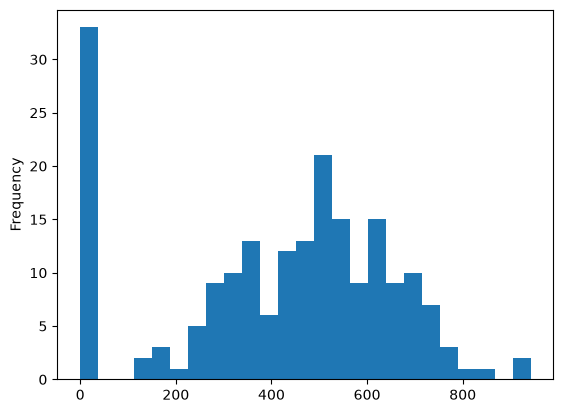

In [43]:
# Check the plot of the data for score to see the distribution
df['score'].plot(kind='hist', bins=25);

In [44]:
# Look for how many values have a -1 value in 'score'
sum(df['score'] == -1)

33

In [45]:
# Drop any row with -1 value in 'score'
df = df[df['score'] != -1]
df.shape

(167, 6)

### 4f. Creating New Columns (mutating) <a id="s4f"></a>

- `assign` can be very helpful in adding a new column
- lambda functions can be used to carry out calculations

In [46]:
# convert age in years to age in (approximate) days
df = df.assign(age_days = df['age'] * 365)
df.head()

,id,first_name,last_name,age,score,value,age_days
1,620,Bill,Woods,46,492,46713.90,16790
2,891,Alexander,Jacobson,48,489,32071.74,17520
5,2049,Stephen,Williams,57,333,138936.92,20805
7,2607,Amber,Garcia,50,536,9367.27,18250
8,2635,David,Coleman,68,351,66035.28,24820


In [47]:
df['age_months'] = df['age'] * 12
df.head()

,id,first_name,last_name,age,score,value,age_days,age_months
1,620,Bill,Woods,46,492,46713.90,16790,552
2,891,Alexander,Jacobson,48,489,32071.74,17520,576
5,2049,Stephen,Williams,57,333,138936.92,20805,684
7,2607,Amber,Garcia,50,536,9367.27,18250,600
8,2635,David,Coleman,68,351,66035.28,24820,816


### 4g. Grouping & Summarizing <a id="s4g"></a>

- group by a particular variable
- calculate summary statistics/metrics within group

In [48]:
df['first_name'].value_counts()

first_name
David        6
Charles      4
Eric         4
James        4
Elizabeth    3
            ..
Lisa         1
Alison       1
Sabrina      1
Andrew       1
Katelyn      1
Name: count, Length: 121, dtype: int64

In [49]:
# caclculate average within each age
df.groupby('first_name').age.mean()

first_name
Aaron        32.0
Alexander    54.0
Alexandra    37.5
Alice        47.0
Alison       40.0
             ... 
Valerie      48.0
Vanessa      35.0
Victor       42.0
Wayne        28.0
William      49.5
Name: age, Length: 121, dtype: float64

## Q&A (10/9)

> Q: How would I get this code to work in order to answer this particular question?  
> A: You would need to make sure you had run the cell where we defined `df` (using `pd.read_csv`) and imported pandas (`import pandas as pd`).

> Q: When is it appropriate to fill in missing data  
> A: Briefly, when missing at random or missing completely at random - but we'll talk about this more soon!

> Q: Will question like these appear on future assignments for further practice.   
> A: Yup - assignments will have these.

> Q: When should I use groupby versus filtering with a condition like df[df['age'] > 30]?  
> A: IF you just need the answer, either is fine. If you want to use the data going forward, filter slightly improved.

> Q: How does groupby handle missing values, and could they affect our comparison?  
> A: By default, pandas excludes missing values from both group keys and aggregation calculations

## Course Announcements (10/9)

Due Sunday (11:59 PM):
- [Pre-course Survey](https://forms.gle/uX95Ph599ep8f1xa8)
- A1
- Q2
- [Group Formation Survey](https://forms.gle/cfhcCeYDnVkVPiRp6) (link also on Canvas; one per group)

Notes: 
- if you submitted pre-course survey OR completed Q1, you've been marked as in the class for #finaid purposes
- Group repos will be created for groups next Mon or Tues (using discussion sections specified on form)
    - For section next week: discuss & attend the one that works for your group
- Lecture participation: complete half of a day's forms -> credit for attendance 

#### Question #3 (WE ALREADY DID THIS ONE)

How would you find the average `score` of people who are over 30 vs. people who are 30 and younger?

Link to form: https://forms.gle/J7MK7x1b1vpWW8bf7

<img src="QRCodes/04_03.png" width="300">

In [50]:
df

,id,first_name,last_name,age,score,value,age_days,age_months
1,620,Bill,Woods,46,492,46713.90,16790,552
2,891,Alexander,Jacobson,48,489,32071.74,17520,576
5,2049,Stephen,Williams,57,333,138936.92,20805,684
7,2607,Amber,Garcia,50,536,9367.27,18250,600
8,2635,David,Coleman,68,351,66035.28,24820,816
...,...,...,...,...,...,...,...,...
194,96371,Sherri,Austin,46,698,29412.01,16790,552
196,97728,Anna,Chambers,37,598,0.00,13505,444
197,98115,Jennifer,Pitts,29,606,6876.75,10585,348
198,98284,Brittany,Jenkins,34,665,43525.88,12410,408


Your responses:

In [52]:
df.groupby('age' > 30).score.mean()

TypeError: '>' not supported between instances of 'str' and 'int'

In [51]:
## YOUR CODE HERE
df.groupby(df['age'] > 30)['score'].mean()

age
False    681.181818
True     486.275641
Name: score, dtype: float64

In [ ]:
# also accomplished the following with .loc, .get('score'), .assign(...)
df[df['age'] > 30]['score'].mean()
df[df['age'] <= 30]['score'].mean()

In words:
- split by age at 30, then average score in each group.
- Answer would differ if you exclude the −1 scores (as we talked about Wed)

Wrong or not ideal answers:
- a loop that keeps two running totals and two counters. <- could do this; less efficent and more effort
- made up methods (.average())
- incorrect filters: `(age > 30) & (age <= 30)` <- can't both be true
- an average of each age’s average, which gives the wrong result when ages repeat

### 4h. Sorting Rows (arrange) <a id="s4h"></a>

- specify order in which to display rows

In [53]:
df.head()

,id,first_name,last_name,age,score,value,age_days,age_months
1,620,Bill,Woods,46,492,46713.90,16790,552
2,891,Alexander,Jacobson,48,489,32071.74,17520,576
5,2049,Stephen,Williams,57,333,138936.92,20805,684
7,2607,Amber,Garcia,50,536,9367.27,18250,600
8,2635,David,Coleman,68,351,66035.28,24820,816


In [54]:
# sort by values in age
df = df.sort_values(by = ['age'], ascending=True)
df.head()

,id,first_name,last_name,age,score,value,age_days,age_months
160,84812,Amanda,Williams,14,749,5241.51,5110,168
151,81282,Emily,Medina,23,775,9116.03,8395,276
132,70735,Eric,Olson,27,665,3975.59,9855,324
29,15887,Cassandra,Mann,27,684,17864.92,9855,324
155,83528,Brenda,Green,28,794,5233.10,10220,336


## 5. Combining Datasets <a id="s5"></a>
![](img/join.png)

In [55]:
## Create two DataFrames
left = pd.DataFrame({'key': ['A', 'B', 'C', 'D'], 'value': np.random.randn(4)})    
right = pd.DataFrame({'key': ['B', 'D', 'E', 'F'], 'value': np.random.randn(4)})

In [56]:
left

,key,value
0,A,-0.104714
1,B,-0.762571
2,C,-1.437548
3,D,0.609294


In [57]:
right

,key,value
0,B,0.520362
1,D,-1.469364
2,E,1.032784
3,F,-2.764225


In [58]:
left.merge?

Signature:
left.merge(
    right: 'DataFrame | Series',
    how: 'MergeHow' = 'inner',
    on: 'IndexLabel | AnyArrayLike | None' = None,
    left_on: 'IndexLabel | AnyArrayLike | None' = None,
    right_on: 'IndexLabel | AnyArrayLike | None' = None,
    left_index: 'bool' = False,
    right_index: 'bool' = False,
    sort: 'bool' = False,
    suffixes: 'Suffixes' = ('_x', '_y'),
    copy: 'bool | None' = None,
    indicator: 'str | bool' = False,
    validate: 'MergeValidate | None' = None,
) -> 'DataFrame'
Docstring:
Merge DataFrame or named Series objects with a database-style join.

A named Series object is treated as a DataFrame with a single named column.

The join is done on columns or indexes. If joining columns on
columns, the DataFrame indexes *will be ignored*. Otherwise if joining indexes
on indexes or indexes on a column or columns, the index will be passed on.
When performing a cross merge, no column specifications to merge on are
allowed.

.. warning::

    If both key c

In [59]:
# inner merge by default
pd.merge(left, right, on='key')

,key,value_x,value_y
0,B,-0.762571,0.520362
1,D,0.609294,-1.469364


In [60]:
# same as above
pd.merge(left, right, on='key', how='inner')

,key,value_x,value_y
0,B,-0.762571,0.520362
1,D,0.609294,-1.469364


In [61]:
# right merge
pd.merge(left, right, on='key', how='right')

,key,value_x,value_y
0,B,-0.762571,0.520362
1,D,0.609294,-1.469364
2,E,NaN,1.032784
3,F,NaN,-2.764225


In [62]:
# left merge
pd.merge(left, right, on='key', how='left')

,key,value_x,value_y
0,A,-0.104714,NaN
1,B,-0.762571,0.520362
2,C,-1.437548,NaN
3,D,0.609294,-1.469364


In [63]:
# outer join
pd.merge(left, right, on='key', how='outer')

,key,value_x,value_y
0,A,-0.104714,NaN
1,B,-0.762571,0.520362
2,C,-1.437548,NaN
3,D,0.609294,-1.469364
4,E,NaN,1.032784
5,F,NaN,-2.764225


In [ ]:
# question from 1P
# if you only want those not in either
temp = pd.merge(left, right, on='key', indicator=True, how='outer')
temp[temp["_merge"] != "both"]
# temp

# works on more recent version of pandas
# pd.merge(left, right, on='key', how='left_anti')

#### Question #4

If table A had 5 rows and table B had 5 rows and 3 of those rows in each table were from the same observations present in the *other* table, how many rows would be present if an **inner merge** were carried out?

- A) 3
- B) 5
- C) 10
- D) 13
- E) Totally unsure

#### Question #5

If table A had 5 rows and table B had 5 rows and 3 of those rows in each table were from the same observations present in the *other* table, how many rows would be present if a **left merge** were carried out?

- A) 3
- B) 5
- C) 10
- D) 13
- E) Totally unsure

Link to Form: https://forms.gle/jkS8bBVu3c8sFark9

<img src="QRCodes/04_04.png" width="300">

BELOW THIS IS NOT INCLUDED ON THE QUIZ. IT IS JUST AN FYI, SO I WILL GO THROUGH IT QUICKLY.

## 6. Getting Data Directly from the Internet <a id="s6"></a>

Your data don't have to be saved on your computer before you load them into pandas. A few common approaches:
1. **Direct file access:** pass a URL straight to `pd.read_csv()` (or another `pd.read_*` function)
2. **Web scraping:** download a web page's HTML and pull the data out of it
3. **APIs:** send requests to a service that returns well-structured data

### 6a. Direct File Access <a id="s6a"></a>

GitHub, Google Drive and Dropbox can all give you a link that loads a file without downloading it first. For a file on GitHub, add `?raw=True` to the end of the file's URL.

Here, we'll load UCSD's Fall 2025 course schedule, compiled by Prof. Jason Fleischer in his [UCSDHistEnrollData](https://github.com/jasongfleischer/UCSDHistEnrollData) repo.

In [ ]:
# UCSD course schedule for Fall 2025
url = 'https://github.com/jasongfleischer/UCSDHistEnrollData/blob/master/data/schedules/FA25.tsv?raw=True'

# This is read_csv(), but the file is a TSV (tab-separated values).
# The sep argument tells pandas what separates the columns.
enroll = pd.read_csv(url, sep='\t')
enroll.shape

In [ ]:
enroll.head()

In [ ]:
# Sections of COGS 108 last fall
enroll[enroll['subj_course_id'] == 'COGS 108']

In [ ]:
# Total seats in each COGS course
cogs = enroll[enroll['subj_course_id'].str.startswith('COGS ')]
cogs.groupby('subj_course_id')['total_seats'].sum().sort_values(ascending=False).head(10)

#### Think-Pair-Share

Does COGS 500 really have ~190,000 seats? What's going on, and how would you handle it before analyzing enrollment?

In [ ]:
# 9999 is a placeholder for 'no seat limit' (independent study, research, etc.)
sum(cogs['total_seats'] == 9999)

#### Your Turn

Excluding the 9999 placeholders, which COGS course had the most seats in Fall 2025? How many seats did it have?

In [ ]:
## YOUR CODE HERE

### 6b. Web Scraping <a id="s6b"></a>

`requests` is a Python library for sending requests to websites. It returns whatever the site sends back: an HTML page, a file, or data from an API (more on APIs below).

`BeautifulSoup` is the standard Python library for web scraping. It gives you tools to find and pull data out of HTML tags.

It's easiest to show with an example. Let's scrape the list of repositories from my GitHub profile page.

In [ ]:
import requests                # send URL requests and receive the data back
from bs4 import BeautifulSoup  # the most widely used web scraper in Python

# Request my GitHub repositories page
page = requests.get('https://github.com/shanellis?tab=repositories')

# The content we get back is a messy HTML file.
# It goes on for pages, so we only print the first 1000 characters.
print(page.text[:1000])

Web scraping is an exercise in patience and careful reading of messy HTML. Modern web pages have hundreds or thousands of tags, and you have to figure out which ones hold the data you want. This is a manual, detailed and often frustrating process.

The usual workflow:
1. Open the page in your browser, right-click the thing you want, and choose **Inspect** to see its HTML.
2. Find a tag or attribute that wraps every item you want (here, each repository).
3. Use `soup.find_all()` to grab all of those items, then dig into each one for the pieces you need.

In [ ]:
soup = BeautifulSoup(page.text, 'html.parser')

# Each repository on the page is a list item (<li>) with the attribute itemprop="owns".
# (itemprop attributes are standard labels that sites add for search engines, so they
# tend to change less often than a site's styling.)
#
# Last spring, this example found each <li> by its CSS class instead:
#   'col-12 d-flex flex-justify-between width-full py-4 border-bottom color-border-muted public source'
# By this fall, GitHub had changed its HTML and that search found nothing.
# Scrapers break without warning whenever a site changes!
repositories = soup.find_all('li', itemprop='owns')
print(len(repositories), 'repositories found')

# Each <li> is just the outer casing; pull the pieces we want out of each one
repo_data = []
for repo in repositories:
    name_tag = repo.find('a', itemprop='name codeRepository')
    description_tag = repo.find('p', itemprop='description')
    language_tag = repo.find('span', itemprop='programmingLanguage')
    star_tag = repo.find('a', href=lambda href: href and href.endswith('/stargazers'))

    repo_data.append({
        'name': name_tag.text.strip() if name_tag else None,
        'description': description_tag.text.strip() if description_tag else None,
        'language': language_tag.text.strip() if language_tag else None,
        'stars': star_tag.text.strip() if star_tag else '0',
    })

scraped_repos = pd.DataFrame(repo_data)
scraped_repos

In [ ]:
# Everything scraped comes back as text, even the star counts
scraped_repos.dtypes

#### Question #6

What type/format of output comes back from `requests.get(URL).text` when the URL is a regular web page?

- A) CSV
- B) HTML
- C) JSON
- D) API
- E) I'm lost

Link to Form: https://forms.gle/bui7M1ThNwM3hxXC6

<img src="QRCodes/04_05.png" width="300">

### 6c. Application Programming Interfaces (APIs) <a id="s6c"></a>

- APIs are basically a way for software to talk to software
    - They are an interface into an application / website / database designed for computers / software.
- Web APIs work over HTTP. A *REST* API uses standard HTTP methods on resources:
    - `GET` retrieves data (what we'll do here)
    - `POST` creates something new; `PUT`/`PATCH` update it; `DELETE` removes it
- Good APIs are documented: the docs tell you what data you can get and how to ask for it. Read them!

Notes on APIs:
- Follow API guidelines!
- These guidelines typically specify the number / rate / size of requests. Break them and you can be blocked.

#### GitHub API

GitHub has a REST API at https://api.github.com/ (docs: https://docs.github.com/en/rest). You add specifiers to the URL for what you're looking for.

For example, the following URL returns information about the user 'ShanEllis':

https://api.github.com/users/shanellis

<center>
<img src="img/github.png" alt="sql" height="100" width="100">
</center>

**Rate limits:** without a token, GitHub allows 60 requests per hour *per IP address*. Many datahub users may share an IP address, so if you get a `403` error, you've hit the limit. Wait a bit, or use a token (see OAuth below).

In [ ]:
# Request data from the GitHub API on a particular user
user_resp = requests.get('https://api.github.com/users/shanellis')
user_resp.status_code   # 200 means success

In [ ]:
# The content we get back is a messily organized json file
user_resp.content

#### Think-Pair-Share

What data file/format are these output?

#### Working with these data...

JSON maps neatly onto Python: JSON *objects* become **dictionaries** and JSON *arrays* become **lists**. `.json()` does that conversion for us.

In [ ]:
# convert the JSON text into a Python dictionary
user = user_resp.json()
type(user)

In [ ]:
# the keys are the fields GitHub sends back
user.keys()

In [ ]:
# access a single value by its key, like any dictionary
user['public_repos']

In [ ]:
# json_normalize turns that dictionary into a (one-row) DataFrame
git_data = pd.json_normalize(user)

In [ ]:
# Check out the pandas df full of data
git_data

#### Getting many results at once: a user's repositories

Most APIs let you customize a request with **query parameters** (passed with `params=`) and **headers** (passed with `headers=`). Here we ask for up to 100 repositories, most recently updated first, and check that the request worked before using the data.

In [ ]:
import os

username = 'shanellis'

# Headers: ask for GitHub's JSON format, and add a token if you've set one (see OAuth below).
# Never paste a token directly into a notebook you might share or push to GitHub.
headers = {'Accept': 'application/vnd.github+json'}
token = os.environ.get('GITHUB_TOKEN')
if token:
    headers['Authorization'] = f'Bearer {token}'

# Query parameters: up to 100 repos (the max per request), most recently pushed first
params = {'per_page': 100, 'sort': 'pushed'}

repos_resp = requests.get(f'https://api.github.com/users/{username}/repos',
                          headers=headers, params=params)

# Stop with an informative error if the request failed (e.g., 403 = rate limit hit)
repos_resp.raise_for_status()
print('Requests left this hour:', repos_resp.headers['X-RateLimit-Remaining'])

repos = pd.json_normalize(repos_resp.json())
repos.shape

In [ ]:
# Under the hood, this response is a *list* of dictionaries, one per repo
repo_list = repos_resp.json()
print(type(repo_list), len(repo_list))
repo_list[0]['name']

In [ ]:
# ~100 columns of information per repo; keep the ones we care about
repo_df = repos[['name', 'language', 'stargazers_count', 'forks_count', 'fork', 'pushed_at']].copy()
repo_df['pushed_at'] = pd.to_datetime(repo_df['pushed_at'])
repo_df.head(10)

In [ ]:
# Unlike the scraped table, these columns already have useful types
# (and the web page only lists 30 repos at a time; the API returned them all)
repo_df.dtypes

In [ ]:
# From here, it's just pandas: which languages are most common?
repo_df['language'].value_counts(dropna=False)

#### Filtering on the server: recent commits to pandas

Query parameters can also filter results *before* they're sent to you. The pandas library itself is developed on GitHub, so let's get the commits to pandas from the last 30 days.

In [ ]:
from datetime import datetime, timedelta, timezone

# GitHub expects dates in ISO 8601 format, e.g. 2026-09-04T03:15:00+00:00
since = (datetime.now(timezone.utc) - timedelta(days=30)).isoformat()

# per_page maxes out at 100; to get more you'd also request page=2, page=3, ...
commits_resp = requests.get('https://api.github.com/repos/pandas-dev/pandas/commits',
                            headers=headers, params={'since': since, 'per_page': 100})
commits_resp.raise_for_status()

# json_normalize flattens nested JSON: commit -> author -> date becomes 'commit.author.date'
commits = pd.json_normalize(commits_resp.json())
commits = commits[['sha', 'commit.author.name', 'commit.author.date', 'commit.message']]
commits['date'] = pd.to_datetime(commits['commit.author.date'])
commits.head()

In [ ]:
# Who's committing to pandas?
commits['commit.author.name'].value_counts().head(10)

In [ ]:
# ...and on which days of the week?
commits['date'].dt.day_name().value_counts()

### 6d. Authorized Access: OAuth <a id="s6d"></a>

Open Authorization is a protocol to authorize access (of a user / application) to an API.

OAuth provides a secure way to 'log-in' without using account names and passwords. 

It is effectively a set of keys, and passwords you can use to access APIs.

Even APIs that don't *require* authorization (like GitHub's) usually let you make many more requests with a token. To try it with GitHub, create a personal access token (GitHub → Settings → Developer settings) and make it available as an environment variable named `GITHUB_TOKEN`. The code above picks it up automatically, so the token itself never appears in your notebook.

### 6e. Web Scraping vs. APIs <a id="s6e"></a>

Web scraping and APIs are different approaches:

- APIs are an interface to interact with an application, designed for programmatic use
    - They allow systematic, controlled access to (for example) and applications database
    - They typically return structured (friendly) data 

- Web scraping (typically) involves navigating through the internet, programmatically following an architecture built for humans
    - This can be hard to systematize, being dependent on the idiosyncracies of a web page, at the time you request it
    - This typically returns relatively unstructured data
    - This entails much more wrangling of the data

## 7. Where to Find Data? <a id="s7"></a>

The project guidelines keep an up-to-date list of places to look for datasets (search engines, curated collections, government, social science and science data), along with tips on choosing one:

**[How to Find Datasets (COGS 108 Project Guidelines)](https://github.com/COGS108/Projects/blob/fa26/FinalProject_Guidelines.md#how-to-find-datasets)**

Before you settle on a dataset, also check the [Data Requirements](https://github.com/COGS108/Projects/blob/fa26/FinalProject_Guidelines.md#data-requirements) and the [off-limits ("taboo") topics and datasets](https://github.com/COGS108/Projects/blob/fa26/FinalProject_Guidelines.md#taboo-topics).

## 8. Notes on Working with Data <a id="s8"></a>

### 8a. Data Science is Ad-Hoc <a id="s8a"></a>

- It is part of the job description to put things together that were not designed to go together.
- We do not have universal solutions, but haphazard, idiosyncratic systems, for data collection, storage and analysis.
- Data is everywhere. But relatively little of it was collected *as data*.

### 8b. Data Collection, Curation, and Storage are Difficult <a id="s8b"></a>

- It can be difficult to choose broadly useful standards
- Take time to think about your data, and how you will load, store, organize and save it

### 8c. Data is Inherently Noisy <a id="s8c"></a>

- We live in a messy, noisy, world, with messy, noisy, people, using messy, noisy instruments.
- There is no perfect data. 
    - There is better / or worse data, given the context.

### 8d. Different Objectives <a id="s8d"></a>

- Humans and computers are different.
- We interact with '*data*' in different ways.
- This underlies many aspects of data wrangling
    - The 'friendliness' of data types / files
    - The difference between web scraping and APIs
    - A disconnect between data in the real world, and data we want to use

### 8e. So... What to Do? <a id="s8e"></a>

- Think about how your data are stored & its structure?
- Look at your data before you anayze it
    - are there missing values? 
    - outlier values? 
- Are your data trustworthy? 
    - source?
    - how was it generated?

### 8f. Specific Recommendations <a id="s8f"></a>

- Prioritize using well structured, common, open file types
    - Take advantage of existing tools to deal with these files (numpy, pandas, etc.)

- Look into, and then follow, common conventions
    - Minimize custom objects, workflows and data files 
- Look for APIs. Ask if they are available.
    - Acknowledge that web scraping and/or wrangling unstructured data are complex / long tasks

- Think about data flow from the beginning. Organize your data pipeline, consider the 'wrangling' aspects throughout
    - Set yourself up with well organized, labelled approach to your data
    - Think about when and how you might want/need to save out intermediate results.